# 📚 Library Management System Analysis
## 1. Project Introduction
This project provides an end-to-end exploratory data analysis of a college library management system. We analyze book circulation, membership engagement, category popularity, borrowing trends, and fine collections using Python and Pandas to support data-driven library resource decisions.

## 2. Import Libraries

In [1]:
# Import required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

## 3. Load Datasets

In [2]:
# Load all four datasets from the dataset directory
books = pd.read_csv('../dataset/raw/books.csv')
members = pd.read_csv('../dataset/raw/members.csv')
borrowing = pd.read_csv('../dataset/raw/borrowing.csv')
fines = pd.read_csv('../dataset/raw/fines.csv')

print(f"Books: {books.shape[0]} rows, {books.shape[1]} columns")
print(f"Members: {members.shape[0]} rows, {members.shape[1]} columns")
print(f"Borrowing: {borrowing.shape[0]} rows, {borrowing.shape[1]} columns")
print(f"Fines: {fines.shape[0]} rows, {fines.shape[1]} columns")

Books: 50 rows, 9 columns
Members: 50 rows, 8 columns
Borrowing: 320 rows, 7 columns
Fines: 106 rows, 7 columns


## 4. Data Understanding

In [3]:
# Inspect sample records from each table
print("--- Books Sample ---")
display(books.head(3))

print("--- Members Sample ---")
display(members.head(3))

print("--- Borrowing Sample ---")
display(borrowing.head(3))

print("--- Fines Sample ---")
display(fines.head(3))

--- Books Sample ---


,book_id,title,author,category,isbn,publication_year,total_copies,available_copies,price
0,B101,Designing Data-Intensive Applications,Martin Kleppmann,Computer Science,978-1449373320,2017,8,8,46.97
1,B102,Clean Code,Robert C. Martin,Computer Science,978-0132350884,2008,6,6,16.25
2,B103,Introduction to Algorithms,Thomas H. Cormen,Computer Science,978-0262033848,2009,5,5,28.75


--- Members Sample ---


,member_id,first_name,last_name,email,phone,membership_type,registration_date,status
0,M101,James,Smith,james.smith1@example.com,+1-555-479-6820,General,2023-05-02,Suspended
1,M102,Emma,Johnson,emma.johnson2@example.com,+1-555-799-2169,Faculty,2023-11-22,Inactive
2,M103,Liam,Williams,liam.williams3@example.com,+1-555-846-5010,Premium,2023-04-08,Active


--- Borrowing Sample ---


,borrow_id,book_id,member_id,borrow_date,due_date,return_date,status
0,BR1001,B138,M116,2024-02-04,2024-02-18,2024-02-08,Returned
1,BR1002,B143,M127,2024-06-21,2024-07-05,2024-06-29,Returned
2,BR1003,B114,M117,2025-05-04,2025-05-18,2025-05-26,Returned


--- Fines Sample ---


,fine_id,borrow_id,member_id,fine_amount,fine_date,payment_status,payment_date
0,FN501,BR1003,M117,12.0,2025-05-26,Paid,2025-05-29
1,FN502,BR1007,M109,18.0,2024-06-19,Paid,2024-06-20
2,FN503,BR1009,M134,15.0,2024-03-05,Paid,2024-03-06


In [4]:
# Check missing values
print("Missing values in Books:")
print(books.isnull().sum())
print("\nMissing values in Members:")
print(members.isnull().sum())
print("\nMissing values in Borrowing:")
print(borrowing.isnull().sum())
print("\nMissing values in Fines:")
print(fines.isnull().sum())

Missing values in Books:
book_id             0
title               0
author              0
category            0
isbn                0
publication_year    0
total_copies        0
available_copies    0
price               0
dtype: int64

Missing values in Members:
member_id            0
first_name           0
last_name            0
email                0
phone                0
membership_type      0
registration_date    0
status               0
dtype: int64

Missing values in Borrowing:
borrow_id      0
book_id        0
member_id      0
borrow_date    0
due_date       0
return_date    0
status         0
dtype: int64

Missing values in Fines:
fine_id            0
borrow_id          0
member_id          0
fine_amount        0
fine_date          0
payment_status     0
payment_date      32
dtype: int64


## 5. Data Cleaning

In [5]:
# Clean whitespace and strip strings
for col in ['book_id', 'title', 'author', 'category', 'isbn']:
    books[col] = books[col].astype(str).str.strip()

for col in ['member_id', 'first_name', 'last_name', 'email', 'phone', 'membership_type', 'status']:
    members[col] = members[col].astype(str).str.strip()

# Convert dates to datetime format
members['registration_date'] = pd.to_datetime(members['registration_date'])
borrowing['borrow_date'] = pd.to_datetime(borrowing['borrow_date'])
borrowing['due_date'] = pd.to_datetime(borrowing['due_date'])
borrowing['return_date'] = pd.to_datetime(borrowing['return_date'])

fines['fine_date'] = pd.to_datetime(fines['fine_date'])
fines['payment_date'] = pd.to_datetime(fines['payment_date'])

# Drop duplicates if any exist
books = books.drop_duplicates()
members = members.drop_duplicates()
borrowing = borrowing.drop_duplicates()
fines = fines.drop_duplicates()

print("Data cleaning completed successfully.")

Data cleaning completed successfully.


## 6. Exploratory Data Analysis

In [6]:
# Calculate core summary metrics
total_books = len(books)
total_members = len(members)
total_borrowings = len(borrowing)
total_fines = fines['fine_amount'].sum()
collected_fines = fines[fines['payment_status'] == 'Paid']['fine_amount'].sum()
overdue_records = (borrowing['return_date'] > borrowing['due_date']).sum()

kpi_summary = pd.DataFrame({
    'Metric': ['Total Books', 'Total Members', 'Total Borrowings', 'Overdue Loans', 'Total Fines ($)', 'Collected Fines ($)'],
    'Value': [total_books, total_members, total_borrowings, overdue_records, f"${total_fines:,.2f}", f"${collected_fines:,.2f}"]
})
display(kpi_summary)

,Metric,Value
0,Total Books,50
1,Total Members,50
2,Total Borrowings,320
3,Overdue Loans,106
4,Total Fines ($),"$1,695.00"
5,Collected Fines ($),"$1,273.50"


In [7]:
# Merge borrowing with books and members
merged_data = borrowing.merge(books, on='book_id').merge(members, on='member_id')
display(merged_data[['borrow_id', 'title', 'category', 'first_name', 'last_name', 'borrow_date', 'status_x']].head())

,borrow_id,title,category,first_name,last_name,borrow_date,status_x
0,BR1001,Artificial Intelligence: A Modern Approach,Computer Science,Harper,Thomas,2024-02-04,Returned
1,BR1002,Dune,Fiction,Samuel,Nair,2024-06-21,Returned
2,BR1003,Brave New World,Fiction,Benjamin,Taylor,2025-05-04,Returned
3,BR1004,Dune,Fiction,William,Rodriguez,2025-03-15,Returned
4,BR1005,Python for Data Analysis,Data Science,Vikram,Adams,2023-02-24,Returned


## 7. Data Visualization

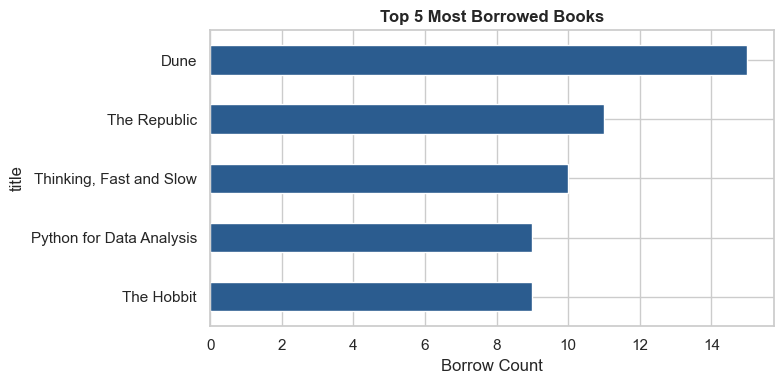

In [8]:
# 1. Top 5 Most Borrowed Books
top_books = merged_data['title'].value_counts().head(5)

plt.figure(figsize=(8, 4))
top_books.plot(kind='barh', color='#2b5c8f')
plt.title('Top 5 Most Borrowed Books', fontsize=12, fontweight='bold')
plt.xlabel('Borrow Count')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

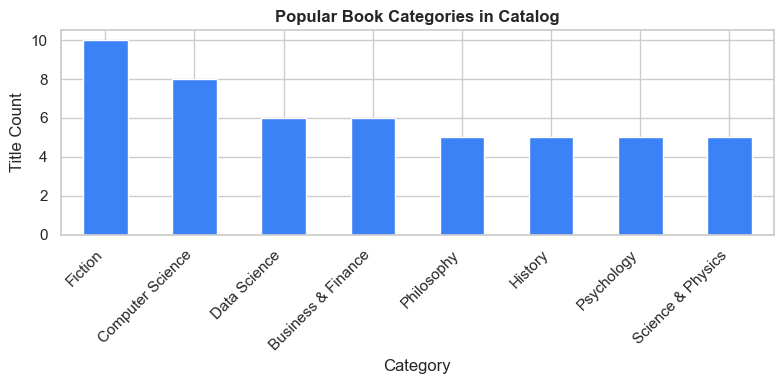

In [9]:
# 2. Popular Book Categories
category_counts = books['category'].value_counts()

plt.figure(figsize=(8, 4))
category_counts.plot(kind='bar', color='#3b82f6')
plt.title('Popular Book Categories in Catalog', fontsize=12, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Title Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

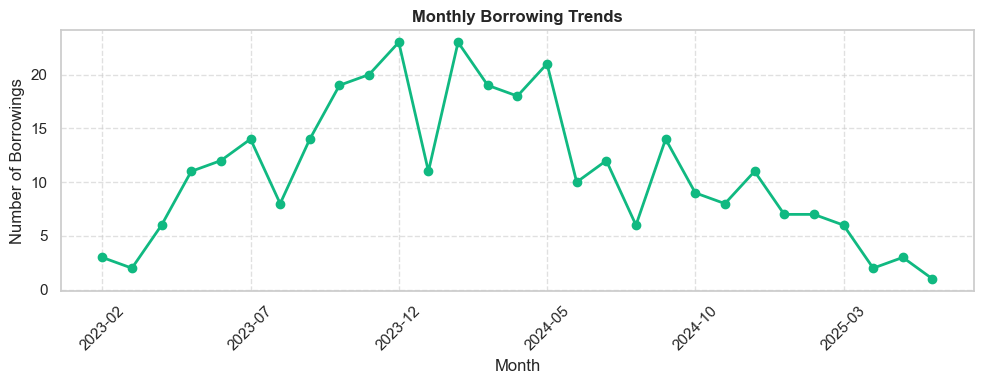

In [10]:
# 3. Monthly Borrowing Trends
borrowing['month'] = borrowing['borrow_date'].dt.to_period('M').astype(str)
monthly_trend = borrowing['month'].value_counts().sort_index()

plt.figure(figsize=(10, 4))
monthly_trend.plot(kind='line', marker='o', color='#10b981', linewidth=2)
plt.title('Monthly Borrowing Trends', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Borrowings')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

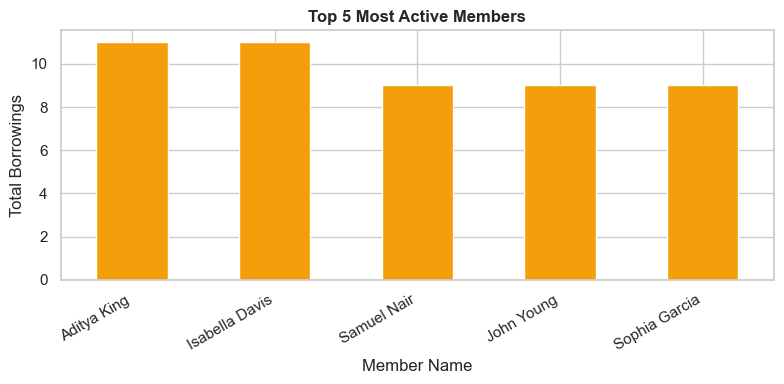

In [11]:
# 4. Top 5 Active Members
merged_data['member_name'] = merged_data['first_name'] + ' ' + merged_data['last_name']
top_members = merged_data['member_name'].value_counts().head(5)

plt.figure(figsize=(8, 4))
top_members.plot(kind='bar', color='#f59e0b')
plt.title('Top 5 Most Active Members', fontsize=12, fontweight='bold')
plt.xlabel('Member Name')
plt.ylabel('Total Borrowings')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

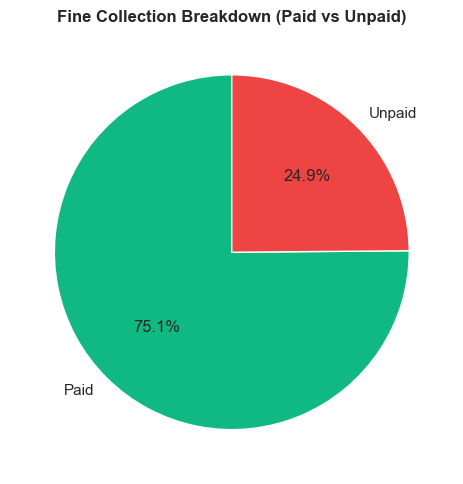

In [12]:
# 5. Fine Collection Status
fine_status = fines.groupby('payment_status')['fine_amount'].sum()

plt.figure(figsize=(5, 5))
fine_status.plot(kind='pie', autopct='%1.1f%%', colors=['#10b981', '#ef4444'], startangle=90)
plt.title('Fine Collection Breakdown (Paid vs Unpaid)', fontsize=12, fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 8. Key Findings
- **High Borrowing Concentration**: The top borrowed titles ('Dune' and 'The Republic') have significantly higher circulation rates than others.
- **Popular Categories**: Fiction, Computer Science, and Data Science are the most popular categories.
- **Late Returns & Fines**: 106 out of 320 borrowing transactions (33.1%) resulted in late returns, generating $1,695.00 in total fines.
- **Fine Recovery**: $1,273.50 (75.1%) of fines have been collected, leaving $421.50 unpaid.
- **Active Patronage**: Active members consistently borrow between 9 to 11 books across the observation period.

## 9. Conclusion
The analysis demonstrates that the library has healthy circulation and strong engagement across science, fiction, and tech categories. By procuring additional copies of top titles and implementing automated return reminders before due dates, the library can improve resource accessibility and minimize overdue penalties.